
# Underwater Image Detection Using Machine Learning

## Project Overview
This project uses deep learning to classify underwater images into different categories.

## Technologies
- Python
- TensorFlow and Keras
- Transfer Learning
- Google Colab
- GitHub

## Objectives
1. Prepare an underwater image dataset.
2. Train an image classification model.
3. Evaluate the model's performance.
4. Predict the category of unseen underwater images.
5. Document the results and publish the project on GitHub.


Python version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Environment setup started!
TensorFlow version: 2.21.0
GPU available: False
Available GPUs: []
All required imports completed successfully!
Total storage: 107.72 GB
Used storage:  20.56 GB
Free storage:  87.14 GB
Project folders created!
Project location: /content/underwater-image-detection
- data
- results
- models


Resolving data files:   0%|          | 0/2766 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/706 [00:00<?, ?it/s]

Some datasets params were ignored: ['images']. Make sure to use only valid params for the dataset builder and to have a up-to-date version of the `datasets` library.


Resolving data files:   0%|          | 0/2766 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/706 [00:00<?, ?it/s]

Images loaded: 200
Available fields: dict_keys(['image'])


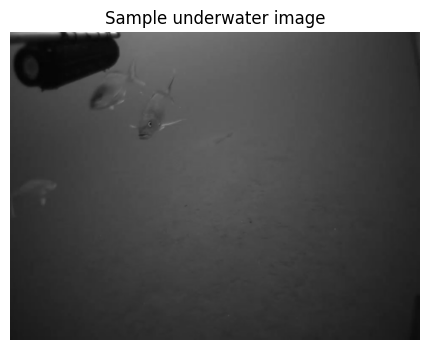

In [2]:
import sys

print("Python version:", sys.version)
print("Environment setup started!")


import tensorflow as tf

print("TensorFlow version:", tf.__version__)

gpus = tf.config.list_physical_devices("GPU")
print("GPU available:", len(gpus) > 0)
print("Available GPUs:", gpus)


import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

print("All required imports completed successfully!")

import shutil

total, used, free = shutil.disk_usage("/content")

print(f"Total storage: {total / (1024**3):.2f} GB")
print(f"Used storage:  {used / (1024**3):.2f} GB")
print(f"Free storage:  {free / (1024**3):.2f} GB")


import os

PROJECT_DIR = "/content/underwater-image-detection"

folders = [
    "data",
    "results",
    "models"
]

for folder in folders:
    os.makedirs(
        os.path.join(PROJECT_DIR, folder),
        exist_ok=True
    )

print("Project folders created!")
print("Project location:", PROJECT_DIR)

for folder in folders:
    print("-", folder)


%pip install -q "huggingface_hub>=0.25,<2.0" datasets


from datasets import load_dataset

dataset = load_dataset(
    "akridge/MOUSS_fish_imagery_dataset_grayscale_small",
    split="train",
    streaming=True
)

samples = []

for item in dataset:
    if item.get("image") is not None:
        samples.append(item)
    if len(samples) >= 200:
        break

print("Images loaded:", len(samples))

import matplotlib.pyplot as plt

print("Available fields:", samples[0].keys())

plt.figure(figsize=(6, 4))
plt.imshow(samples[0]["image"], cmap="gray")
plt.title("Sample underwater image")
plt.axis("off")
plt.show()



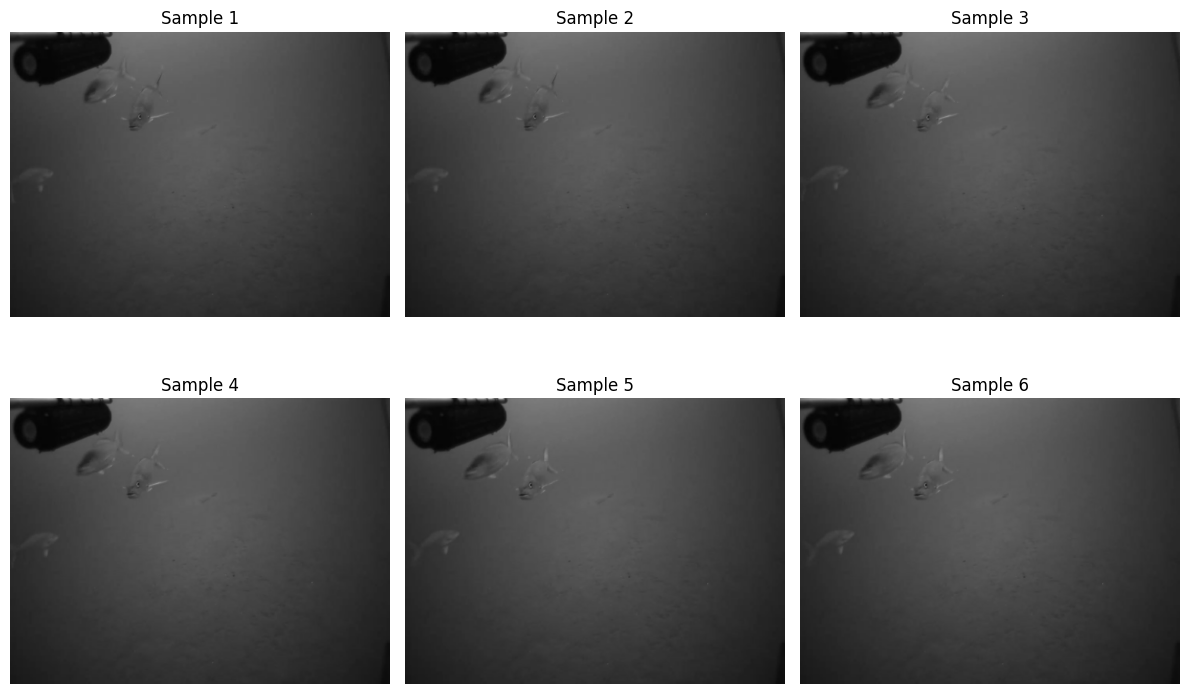

Image 1: size = (968, 728) | mode = RGB
Image 2: size = (968, 728) | mode = RGB
Image 3: size = (968, 728) | mode = RGB
Image 4: size = (968, 728) | mode = RGB
Image 5: size = (968, 728) | mode = RGB


In [4]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))

for i in range(6):
    plt.subplot(2, 3, i + 1)
    plt.imshow(samples[i]["image"], cmap="gray")
    plt.title(f"Sample {i + 1}")
    plt.axis("off")

plt.tight_layout()
plt.show()


for i in range(5):
    image = samples[i]["image"]
    print(
        f"Image {i + 1}:",
        "size =", image.size,
        "| mode =", image.mode
    )



In [5]:

from datasets import load_dataset

dataset = load_dataset(
    "fish-gang/deepscan-dataset",
    split="train",
    streaming=True
)

print("Dataset loaded in streaming mode!")


README.md:   0%|          | 0.00/7.39k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/18 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/18 [00:00<?, ?it/s]

Dataset loaded in streaming mode!


In [6]:

from collections import defaultdict

small_data = defaultdict(list)

for item in dataset:
    label = item["label"]
    label_name = (
        dataset.features["label"].int2str(label)
        if hasattr(dataset, "features") and dataset.features
        else str(label)
    )

    if label_name == "no_fish" and len(small_data["no_fish"]) < 100:
        small_data["no_fish"].append(item["image"])

    elif label_name != "no_fish" and label_name != "unknown_fish" and len(small_data["fish"]) < 100:
        small_data["fish"].append(item["image"])

    if len(small_data["fish"]) >= 100 and len(small_data["no_fish"]) >= 100:
        break

print("Fish images:", len(small_data["fish"]))
print("No-fish images:", len(small_data["no_fish"]))


Fish images: 100
No-fish images: 100


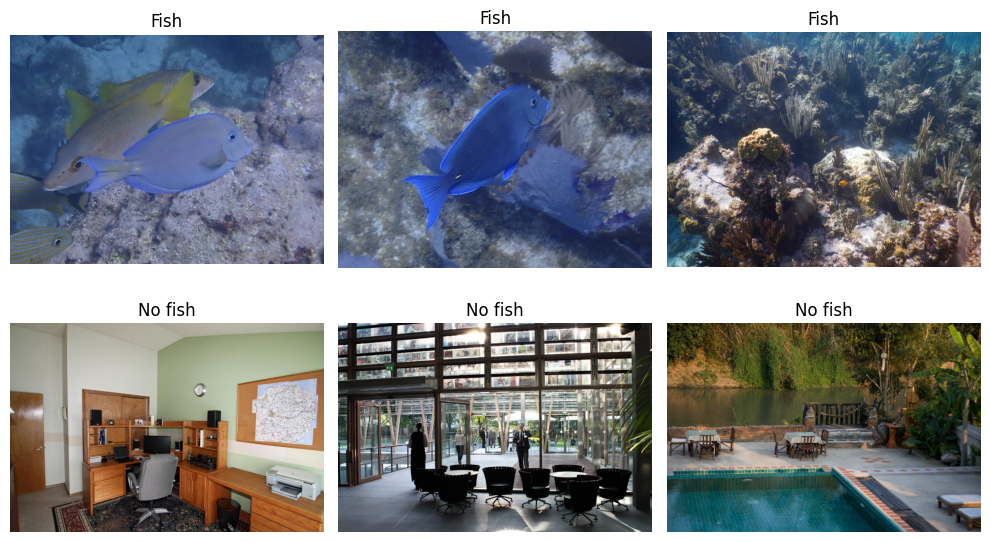

In [7]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 3, figsize=(10, 6))

for i in range(3):
    axes[0, i].imshow(small_data["fish"][i])
    axes[0, i].set_title("Fish")
    axes[0, i].axis("off")

    axes[1, i].imshow(small_data["no_fish"][i])
    axes[1, i].set_title("No fish")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()


In [8]:

import numpy as np
from tensorflow.keras.utils import img_to_array

IMG_SIZE = (224, 224)

images = []
labels = []

# Label 1 = fish
for image in small_data["fish"]:
    image = image.convert("RGB").resize(IMG_SIZE)
    images.append(img_to_array(image) / 255.0)
    labels.append(1)

# Label 0 = no fish
for image in small_data["no_fish"]:
    image = image.convert("RGB").resize(IMG_SIZE)
    images.append(img_to_array(image) / 255.0)
    labels.append(0)

X = np.array(images, dtype=np.float32)
y = np.array(labels, dtype=np.int32)

print("Image array shape:", X.shape)
print("Label array shape:", y.shape)
print("Pixel range:", X.min(), "to", X.max())
print("Fish images:", np.sum(y == 1))
print("No-fish images:", np.sum(y == 0))


Image array shape: (200, 224, 224, 3)
Label array shape: (200,)
Pixel range: 0.0 to 1.0
Fish images: 100
No-fish images: 100


In [9]:

from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training images:", len(X_train))
print("Validation images:", len(X_val))
print("Training class counts:", np.bincount(y_train))
print("Validation class counts:", np.bincount(y_val))


Training images: 160
Validation images: 40
Training class counts: [80 80]
Validation class counts: [20 20]


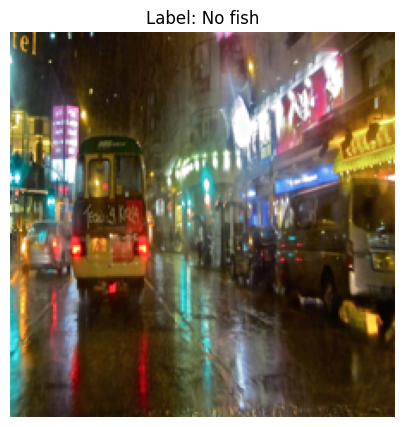

In [10]:

class_names = {0: "No fish", 1: "Fish"}

plt.figure(figsize=(5, 5))
plt.imshow(X_train[0])
plt.title("Label: " + class_names[int(y_train[0])])
plt.axis("off")
plt.show()


In [11]:

from tensorflow.keras.applications import MobileNetV2

base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

print("Pretrained MobileNetV2 loaded!")
print("Base model trainable:", base_model.trainable)


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Pretrained MobileNetV2 loaded!
Base model trainable: False


In [12]:

from tensorflow.keras import layers, models

inputs = keras.Input(shape=(224, 224, 3))

# Convert [0, 1] pixel values to MobileNetV2's expected range
x = layers.Rescaling(scale=2.0, offset=-1.0)(inputs)

# Extract pretrained image features
x = base_model(x, training=False)

# Convert features into a single vector
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)

# Output probability for the fish class
outputs = layers.Dense(1, activation="sigmoid")(x)

model = models.Model(inputs, outputs)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [13]:

history = model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=16,
    validation_data=(X_val, y_val),
    verbose=1
)


Epoch 1/5
10/10 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - accuracy: 0.6313 - loss: 0.7021 - val_accuracy: 0.8500 - val_loss: 0.4266
Epoch 2/5
10/10 ━━━━━━━━━━━━━━━━━━━━ 7s 709ms/step - accuracy: 0.9125 - loss: 0.3158 - val_accuracy: 0.9750 - val_loss: 0.2264
Epoch 3/5
10/10 ━━━━━━━━━━━━━━━━━━━━ 11s 748ms/step - accuracy: 0.9875 - loss: 0.1603 - val_accuracy: 1.0000 - val_loss: 0.1361
Epoch 4/5
10/10 ━━━━━━━━━━━━━━━━━━━━ 9s 899ms/step - accuracy: 1.0000 - loss: 0.0982 - val_accuracy: 1.0000 - val_loss: 0.0984
Epoch 5/5
10/10 ━━━━━━━━━━━━━━━━━━━━ 7s 734ms/step - accuracy: 1.0000 - loss: 0.0664 - val_accuracy: 0.9750 - val_loss: 0.0806


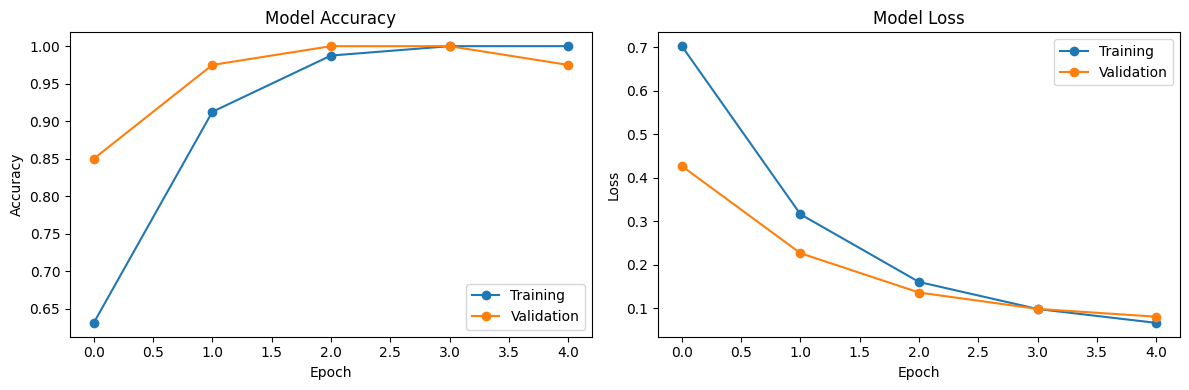

In [14]:

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], marker="o", label="Training")
plt.plot(history.history["val_accuracy"], marker="o", label="Validation")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], marker="o", label="Training")
plt.plot(history.history["val_loss"], marker="o", label="Validation")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


In [15]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

y_prob = model.predict(X_val, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print("Validation accuracy:", accuracy_score(y_val, y_pred))
print("\nClassification report:\n")
print(
    classification_report(
        y_val,
        y_pred,
        labels=[0, 1],
        target_names=["No fish", "Fish"],
        zero_division=0
    )
)


Validation accuracy: 0.975

Classification report:

              precision    recall  f1-score   support

     No fish       0.95      1.00      0.98        20
        Fish       1.00      0.95      0.97        20

    accuracy                           0.97        40
   macro avg       0.98      0.97      0.97        40
weighted avg       0.98      0.97      0.97        40



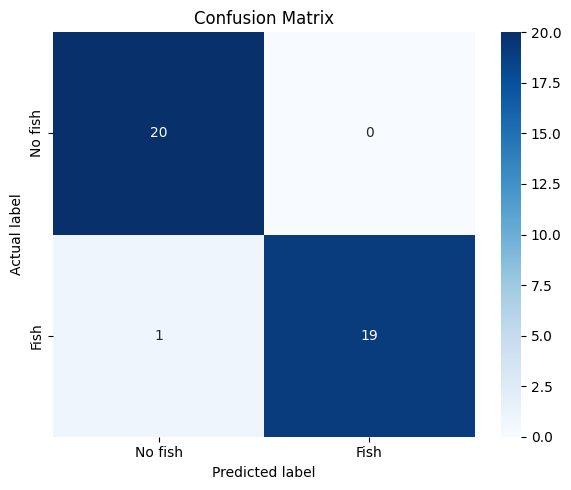

In [16]:

import seaborn as sns

cm = confusion_matrix(y_val, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No fish", "Fish"],
    yticklabels=["No fish", "Fish"]
)

plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()


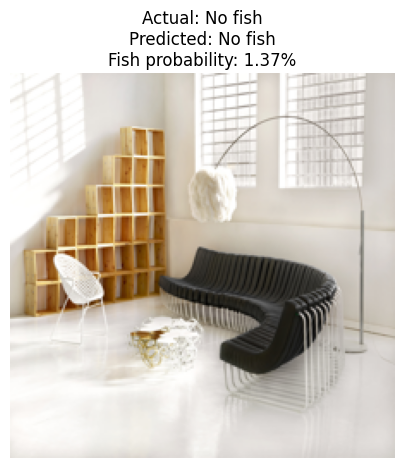

In [17]:

import random

idx = random.randrange(len(X_val))

image = X_val[idx]
actual_label = int(y_val[idx])
probability = float(model.predict(image[np.newaxis, ...], verbose=0)[0][0])

predicted_label = 1 if probability >= 0.5 else 0

plt.figure(figsize=(5, 5))
plt.imshow(image)
plt.title(
    f"Actual: {class_names[actual_label]}\n"
    f"Predicted: {class_names[predicted_label]}\n"
    f"Fish probability: {probability:.2%}"
)
plt.axis("off")
plt.show()


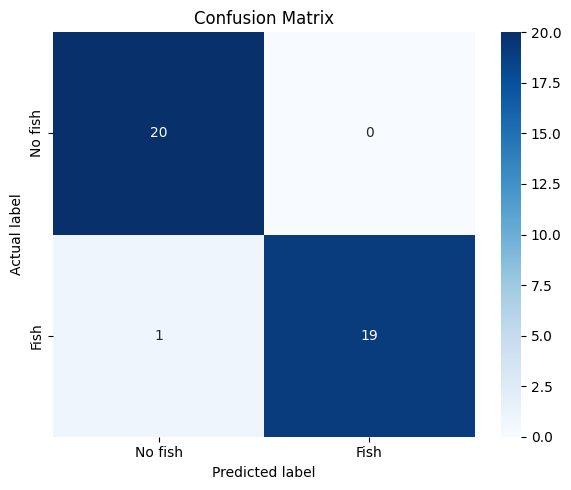

Confusion matrix:
[[20  0]
 [ 1 19]]


In [18]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_val, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No fish", "Fish"],
    yticklabels=["No fish", "Fish"]
)

plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

print("Confusion matrix:")
print(cm)

In [19]:
import os

model_dir = "/content/underwater-image-detection/models"
os.makedirs(model_dir, exist_ok=True)

model_path = os.path.join(
    model_dir,
    "underwater_classifier.keras"
)

model.save(model_path)

print("Model saved successfully!")
print("Location:", model_path)

Model saved successfully!
Location: /content/underwater-image-detection/models/underwater_classifier.keras


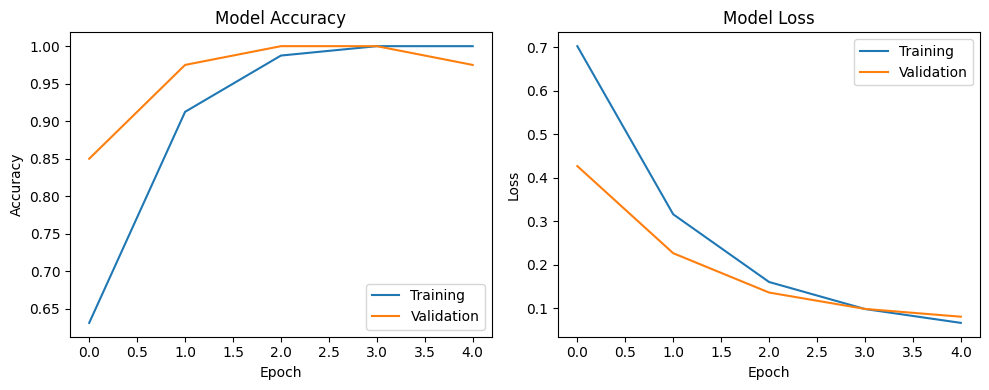

Training graph saved to: /content/underwater-image-detection/results/training_history.png


In [20]:
import os
import matplotlib.pyplot as plt

results_dir = "/content/underwater-image-detection/results"
os.makedirs(results_dir, exist_ok=True)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()

graph_path = os.path.join(results_dir, "training_history.png")
plt.savefig(graph_path, dpi=150, bbox_inches="tight")
plt.show()

print("Training graph saved to:", graph_path)

Saving IMG_20260817_144000.png to IMG_20260817_144000.png


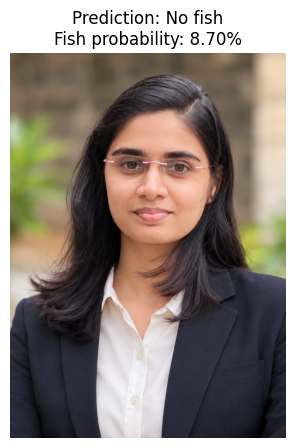

Image: IMG_20260817_144000.png
Predicted class: No fish
Fish probability: 8.70%


In [22]:
from google.colab import files
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

uploaded = files.upload()

for filename in uploaded.keys():
    image = Image.open(filename).convert("RGB")
    resized_image = image.resize((224, 224))

    image_array = np.array(resized_image, dtype=np.float32) / 255.0
    image_array = np.expand_dims(image_array, axis=0)

    probability = float(
        model.predict(image_array, verbose=0)[0][0]
    )

    predicted_class = "Fish" if probability >= 0.5 else "No fish"

    plt.figure(figsize=(6, 5))
    plt.imshow(image)
    plt.title(
        f"Prediction: {predicted_class}\n"
        f"Fish probability: {probability:.2%}"
    )
    plt.axis("off")
    plt.show()

    print("Image:", filename)
    print("Predicted class:", predicted_class)
    print(f"Fish probability: {probability:.2%}")

In [23]:

readme_content = """
# Underwater Image Detection Using Machine Learning

## Project Overview
This project uses deep learning to classify underwater images into two
categories: Fish and No fish.

It uses transfer learning with MobileNetV2, a convolutional neural
network pretrained on ImageNet.

## Objectives
- Classify underwater images as Fish or No fish.
- Apply transfer learning to image classification.
- Evaluate the model using accuracy, precision, recall, and F1-score.
- Test predictions on new images.

## Technologies Used
- Python
- TensorFlow and Keras
- MobileNetV2
- NumPy
- Matplotlib
- Scikit-learn
- Google Colab

## Model Workflow
1. Collect and label underwater images.
2. Resize images to 224 x 224 pixels.
3. Normalize pixel values.
4. Split data into training and validation sets.
5. Train a classification head using MobileNetV2 features.
6. Evaluate the model.
7. Predict the class of a new image.

## Dataset
The initial experiment uses 200 images:
- 100 Fish images
- 100 No fish images

The data is split into 160 training images and 40 validation images.

## Preliminary Results
- Validation accuracy: 97.5%
- Validation images: 40
- Correct predictions: 39 out of 40

These are preliminary results from a small validation set. More images
and testing on an independent dataset are needed to assess generalization.

## Model
The trained model is saved as:
`models/underwater_classifier.keras`

## How to Run
1. Open `Underwater_Image_Detection.ipynb` in Google Colab.
2. Run the notebook cells in order.
3. Train or load the model.
4. Upload an underwater image to test a prediction.

## Project Structure
underwater-image-detection/
- Underwater_Image_Detection.ipynb
- README.md
- models/
- results/
  - training_history.png

## Future Improvements
- Increase the size and diversity of the dataset.
- Evaluate on a separate test set.
- Add data augmentation.
- Test performance on different underwater environments.
- Consider multi-class classification for more marine species.

## Disclaimer
This is an educational machine learning project. Predictions may be
incorrect, especially on images that differ from the training data.
"""

readme_path = "/content/underwater-image-detection/README.md"

with open(readme_path, "w", encoding="utf-8") as f:
    f.write(readme_content)

print("README created:", readme_path)


README created: /content/underwater-image-detection/README.md


In [24]:
import os

project_dir = "/content/underwater-image-detection"

for root, dirs, files_list in os.walk(project_dir):
    dirs[:] = [d for d in dirs if d != "__pycache__"]
    for filename in files_list:
        print(os.path.relpath(os.path.join(root, filename), project_dir))

README.md
models/underwater_classifier.keras
results/training_history.png


In [26]:
import shutil

project_dir = "/content/underwater-image-detection"
zip_path = "/content/underwater-image-detection.zip"

shutil.make_archive(
    "/content/underwater-image-detection",
    "zip",
    project_dir
)

print("ZIP created:", zip_path)

from google.colab import files
files.download("/content/underwater-image-detection.zip")

ZIP created: /content/underwater-image-detection.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>